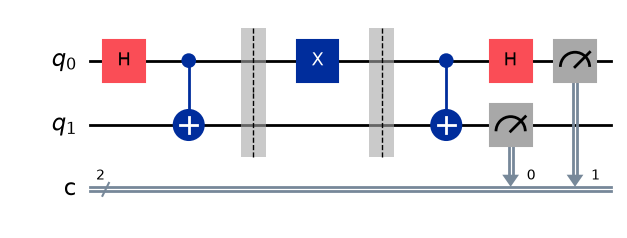

Effect of a guaranteed bit-flip error during transmission:
 sent 01 -> decoded 00 {'00': 1024}
 sent 11 -> decoded 10 {'10': 1024}
\nRandom channel noise, bit-flip probability p = 0.1:
Message   Accuracy    Counts
00        0.905       {'00': 3619, '01': 381}
01        0.906       {'01': 3626, '00': 374}
10        0.897       {'10': 3587, '11': 413}
11        0.893       {'11': 3571, '10': 429}
Overall accuracy: 0.900 (theoretical 1-p = 0.900)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, pauli_error, depolarizing_error
def encode_gate(qc, qubit, bits):
    """Alice's encoding operation for a 2-bit message (b1, b0)."""
    b1, b0 = bits
    if b1 == 0 and b0 == 0:
     pass # I -> message 00
    elif b1 == 0 and b0 == 1:
     qc.x(qubit) # X -> message 01
    elif b1 == 1 and b0 == 0:
     qc.z(qubit) # Z -> message 10
    elif b1 == 1 and b0 == 1:
     qc.z(qubit); qc.x(qubit) # ZX -> message 11
# --- Deterministic effect of a single bit-flip error on the transmitted qubit ---
def superdense_with_flip(bits):
    qc = QuantumCircuit(2, 2)
    qc.h(0); qc.cx(0, 1)
    encode_gate(qc, 0, bits)
    qc.barrier()
    qc.x(0) # channel noise: the transmitted qubit is bit-flipped in transit
    qc.barrier()
    qc.cx(0, 1); qc.h(0)
    qc.measure(0, 1); qc.measure(1, 0)
    return qc
display(superdense_with_flip((0, 0)).draw(output='mpl', style='iqp'))
print("Effect of a guaranteed bit-flip error during transmission:")
for b1 in [0, 1]:
    for b0 in [0, 1]:
      counts = AerSimulator().run(superdense_with_flip((b1, b0)),shots=1024).result().get_counts()
      sent, decoded = f"{b1}{b0}", max(counts, key=counts.get)
    print(f" sent {sent} -> decoded {decoded} {counts}")
# --- Probabilistic channel: each transmitted qubit is bit-flipped with probability p ---
p_flip = 0.10
noise_model = NoiseModel()
noise_model.add_quantum_error(pauli_error([('X', p_flip), ('I', 1 - p_flip)]), 'id', [0])
sim_noisy = AerSimulator(noise_model=noise_model)
def superdense_noisy_channel(bits):
    qc = QuantumCircuit(2, 2)
    qc.h(0); qc.cx(0, 1)
    encode_gate(qc, 0, bits)
    qc.id(0) # idle "transmission" step -- carries the channel noise
    qc.cx(0, 1); qc.h(0)
    qc.measure(0, 1); qc.measure(1, 0)
    return qc
print(f"\\nRandom channel noise, bit-flip probability p = {p_flip}:")
print(f"{'Message':<10}{'Accuracy':<12}{'Counts'}")
shots, total_correct, total = 4000, 0, 0
for b1 in [0, 1]:
    for b0 in [0, 1]:
      msg = f"{b1}{b0}"
      counts = sim_noisy.run(superdense_noisy_channel((b1, b0)),shots=shots).result().get_counts()
      acc = counts.get(msg, 0) / shots
      print(f"{msg:<10}{acc:<12.3f}{counts}")
      total_correct += counts.get(msg, 0); total += shots
print(f"Overall accuracy: {total_correct/total:.3f} (theoretical 1-p = {1-p_flip:.3f})")